# Perch 2.0 zero-shot: where Perch hears each group

Each page is **one minute** of one long-form recording. It shows:

- **Perch boxes** (dashed, numbered #1, #2, ... and playable from the list under the plot): runs of consecutive 2.5 s segments where Perch's summed probability for a group passes that group's threshold. Perch gives no frequency range, so these boxes span the band it hears (60 Hz–16 kHz).
- **Raven boxes** (filled, labelled): the manual annotations at their real frequency range. Turn them on or off with the **Raven labels** radio button.
- **Score track** (below the spectrogram): Perch's score per 2.5 s segment, one lane per group. The dotted line in the middle of each lane is the threshold; shaded = above threshold. A black bar marks a Raven box of that group.

**Hybrid.** When `data/perch_windows/earthchirp_segments.csv` exists (from `scripts/earthchirp_windows.py`), two EarthChirp insect lanes are added: **EC-Insecta** (EarthChirp's insect cosine) and **EC-margin** (that cosine minus the cosine to an ESC-50 urban / geophony reference). The default lanes are then the hybrid: Perch for Aves, Amphibia, Anthropogenic and Weather, EarthChirp for insects. Perch's own Insecta lane stays available, unticked, for comparison. The EC lanes are drawn against the Raven insect boxes.

**Tightened boxes.** When `data/perch_windows/cell_maps.npy` exists (from `scripts/cell_maps.py`), each Perch / EarthChirp box can also be drawn **tightened** in time and frequency. Perch scores a 5 s window from a 16 × 4 grid of cells (312.5 ms × one of 4 frequency rows: 0.06–0.95, 0.95–2.9, 2.9–7.0, 7.0–16 kHz); `cell_maps.py` scores every cell on its own with the same head (EarthChirp: each cell's share of the window's cosine). Inside each box, the cells scoring at least **keep cells ≥** (default 0.5) of the way from the box's median to its highest cell are kept (shaded), rows holding only a few such cells are dropped, and the bounding box of what is left is drawn solid. The player can also play a box **filtered** to its tightened rows or its kept cells. Nothing is learned and no labels are used; 4 rows is coarse, and Perch hears nothing above 16 kHz.

The notebook only reads `data/perch_windows/segment_scores.csv` (from `scripts/zeroshot_windows.py`), `earthchirp_segments.csv` and `cell_maps.npy` if present, the Raven tables and the wavs. It writes nothing.

**Run all cells, then use the viewer in Section 1.**

### Thresholds (summed probability, editable in the viewer)

| Group | Threshold | Audio flagged | How it was chosen | Reliability |
|---|---:|---:|---|---|
| Aves | 0.94 | 14% | max(recall − share flagged) gave 0.916; 0.94 chosen by listening in this viewer | good (listened) |
| Anthropogenic | 0.043 | 10% | top-10% budget; confirmed by listening | good (listened) |
| Amphibia | 0.128 | 8% | max(recall − share flagged), varies 0.11–0.21 across days; confirmed by listening | good (listened) |
| Weather | 0.011 | 9% | max(recall − share flagged) | tentative (5 recordings) |
| Insecta | 0.032 | 79% | insects sing through most of the audio, so a high flagged share is expected; 0.032 chosen by listening | good (listened) |
| Mammalia | 0.013 | 36% | fitted on the only recording with mammals | untestable; **off by default** |
| EC-Insecta (EarthChirp cosine) | 0.42 | 74% | clip-matched start 0.402; 0.42 chosen by listening. The hybrid's insect lane | good (listened) |
| EC-margin (EarthChirp margin) | 0.280 | 72% | flags the same 68% of clip windows as Perch Insecta ≥ 0.032 | not listened to; off by default |

Thresholds differ a lot between groups because about 10,000 of Perch's 14,795 classes are birds: a bird score of 0.9 is ordinary, while an Anthropogenic score of 0.04 is already a signal.


In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "scripts" / "perch_viewer.py").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
os.chdir(ROOT)
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import importlib, perch_viewer as pv
pv = importlib.reload(pv)   # a kernel kept from earlier would otherwise hold stale code / lanes
print("thresholds:", pv.THRESHOLDS)

thresholds: {'Aves': 0.94, 'Amphibia': 0.128, 'Insecta': 0.032, 'Mammalia': 0.013, 'Anthropogenic': 0.043, 'Weather': 0.011, 'EC-Insecta': 0.42, 'EC-margin': 0.28}


## 1. Viewer

| Control | What it does |
|---|---|
| **Audio file** dropdown, ◀ prev rec / next rec ▶ | choose any of the 155 wav files: name, start date and time, length, Raven box count. The 21 files with no Raven table have no Perch scores (spectrogram only) |
| **Minute**, ◀ minute / minute ▶ | move through the recording one minute at a time |
| **find Perch box of** + ◀ prev hit / next hit ▶ | jump to the previous or next minute, across recordings, where Perch flags that group (and tick it) |
| **Raven labels** Show / Hide | overlay the annotated boxes and their labels |
| **Perch boxes** Show / Hide | the dashed Perch boxes on the spectrogram (the score track always shows) |
| group tick boxes + numbers | which groups to draw, and each group's threshold; **reset thresholds** restores the table above |
| **Max kHz**, **Range dB** | display only |
| **Box extent** both / tightened / full band | draw each Perch box tightened to its cells (solid, kept cells shaded), the full-band box (dashed), or both. Only with `cell_maps.npy` |
| **keep cells ≥** | how far from the box's median to its highest cell score a cell must be to be kept (0 = the whole box; higher = tighter). Set it by eye |
| **Listen to a Perch box** list | one row per Perch box on this minute, numbered like the #labels on the spectrogram; click a row to play that box (its tightened span when tightened boxes are drawn; plus **pad** seconds each side, up to 30 s); **▶ play again** replays it |
| **Play** original / band-passed / cell mask | what the list plays: the audio as recorded; only the tightened box's frequency rows (e.g. 0.95–2.9 kHz for most bird boxes); or only its kept cells (0.31 s × one row, everything else muted, padding included). This cuts time and frequency; it does not separate sources, so other sounds in the same rows stay. Clips are peak-normalised. Only with `cell_maps.npy` |
| **▶ load audio of this minute** | puts a player for the 60 s under the plot |

The table above the plot counts, for this minute, Perch boxes and seconds flagged per group, the mean tightened area (share of each box's cells inside its tightened box), and Raven boxes of that group.

In [2]:
viewer = pv.PerchViewer().show()

## 2. Where Perch and Raven agree, per recording

Perch boxes (at the thresholds above) and Raven boxes per group and recording. The EC columns count EarthChirp boxes; their Raven column is the Raven insect boxes. Use it to pick recordings for the viewer: for example, many Raven boxes but few Perch boxes means Perch misses that group there.

In [3]:
seg, raven = viewer.seg, viewer.raven
rows = []
for rec, s in seg.groupby("recording"):
    pb = pv.perch_boxes(s, pv.THRESHOLDS)
    r = {"recording": rec}
    for g in [g for g in pv.VIEW_GROUPS if f"prob_{g}" in seg]:
        rg = "Insecta" if g in pv.EC_GROUPS else g     # EarthChirp lanes are insect lanes
        r[f"{g} Perch"] = int((pb["group"] == g).sum())
        r[f"{g} Raven"] = int(((raven["recording"] == rec) & (raven["group"] == rg)).sum())
    rows.append(r)
summary = pd.DataFrame(rows).set_index("recording")
summary[[c for c in summary if c.split()[0] in pv.DEFAULT_ON]]

,Aves Perch,Aves Raven,Amphibia Perch,Amphibia Raven,Anthropogenic Perch,Anthropogenic Raven,Weather Perch,Weather Raven,EC-Insecta Perch,EC-Insecta Raven
recording,,,,,,,,,,
S01634_20250228_000000,3,2,0,0,0,0,0,0,12,45
S01634_20250228_012000,16,5,0,0,1,0,0,0,11,53
S01634_20250228_024000,15,10,0,0,1,0,0,0,12,66
S01634_20250228_040000,32,34,0,0,1,1,0,0,10,36
S01634_20250228_052000,12,9,0,0,2,0,0,0,46,1
...,...,...,...,...,...,...,...,...,...,...
S01634_20250315_172000,2,29,8,0,10,1,8,1,13,43
S01634_20250315_184000,0,0,1,0,28,1,0,0,2,23
S01634_20250315_200000,7,2,0,0,0,2,0,0,1,1


## 3. Perch-flagged minutes per recording

Each row is a recording and each column one minute; the colour is the share of that minute Perch flags for the group. Bright minutes are where to look.

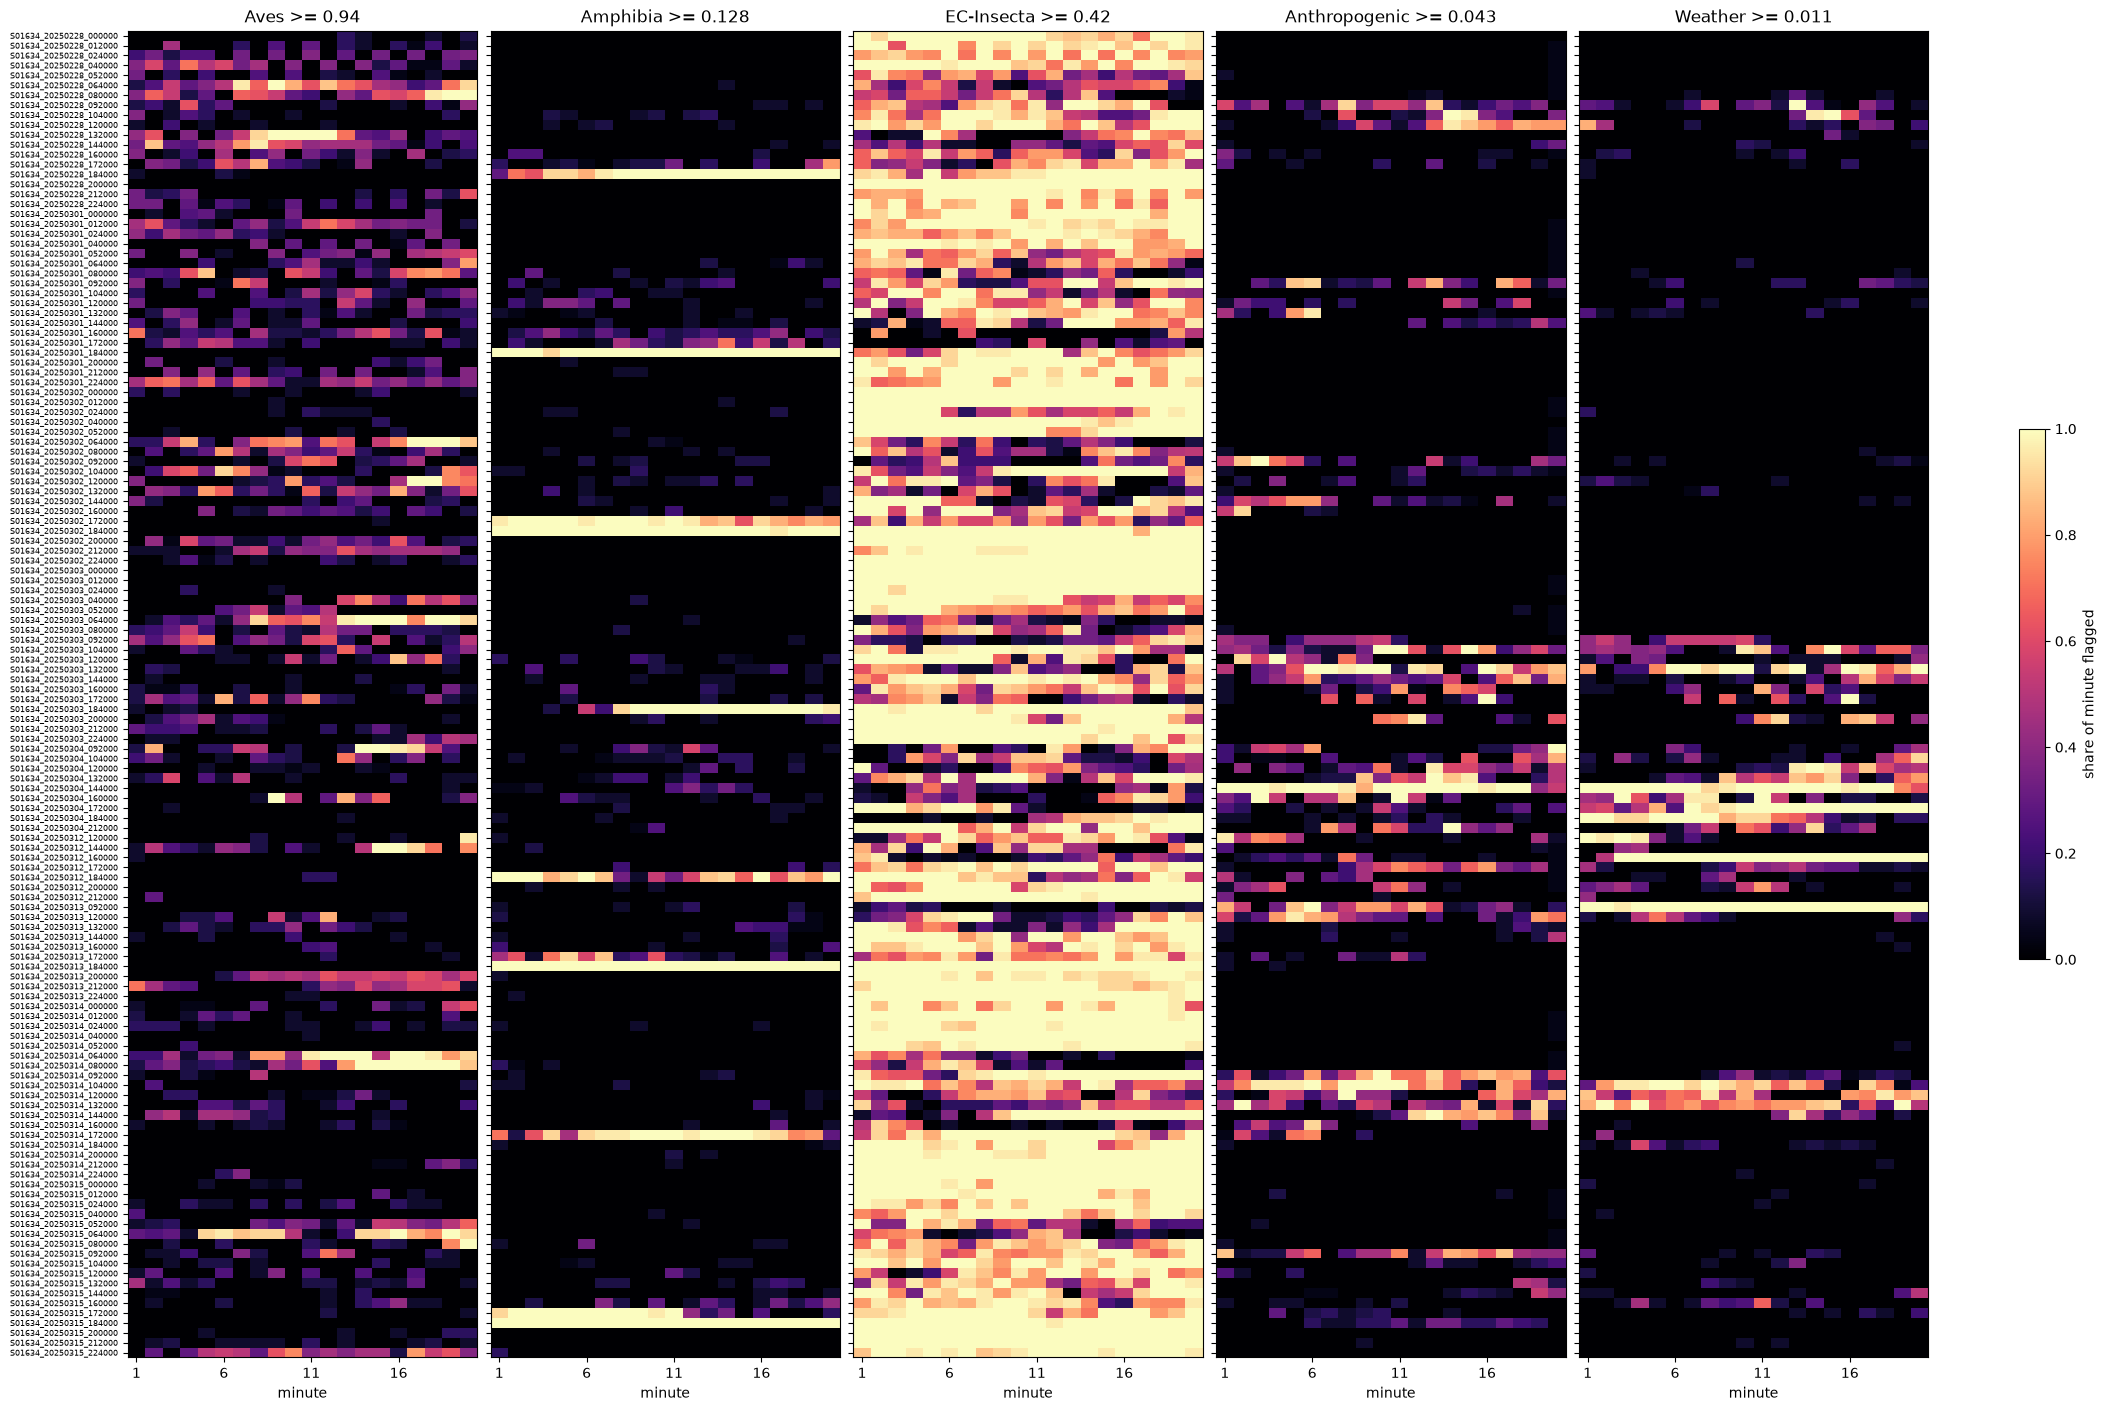

In [4]:
groups = list(pv.DEFAULT_ON)
fig, axes = plt.subplots(1, len(groups), figsize=(4.2 * len(groups), 14), sharey=True, constrained_layout=True)
recs = sorted(seg["recording"].unique())
for ax, g in zip(axes, groups):
    m = seg.assign(minute=(seg["start_s"] // 60).clip(upper=19).astype(int),
                   on=seg[f"prob_{g}"] >= pv.THRESHOLDS[g])
    grid = m.pivot_table(index="recording", columns="minute", values="on", aggfunc="mean").reindex(recs)
    im = ax.imshow(grid.values, aspect="auto", cmap="magma", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{g} >= {pv.THRESHOLDS[g]:g}")
    ax.set_xlabel("minute")
    ax.set_xticks(range(0, 20, 5)); ax.set_xticklabels(range(1, 21, 5))
axes[0].set_yticks(range(len(recs))); axes[0].set_yticklabels(recs, fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.4, label="share of minute flagged")
plt.show()

## 4. One page without the GUI

`plot_page` draws the same picture as the viewer; use it to save a figure. `t0` is the start in seconds. `cells=viewer.cells, box_mode="tightened", kappa=0.5` adds the tightened boxes; the returned table then has `t_begin`, `t_end`, `lo_khz`, `hi_khz` and `area`.

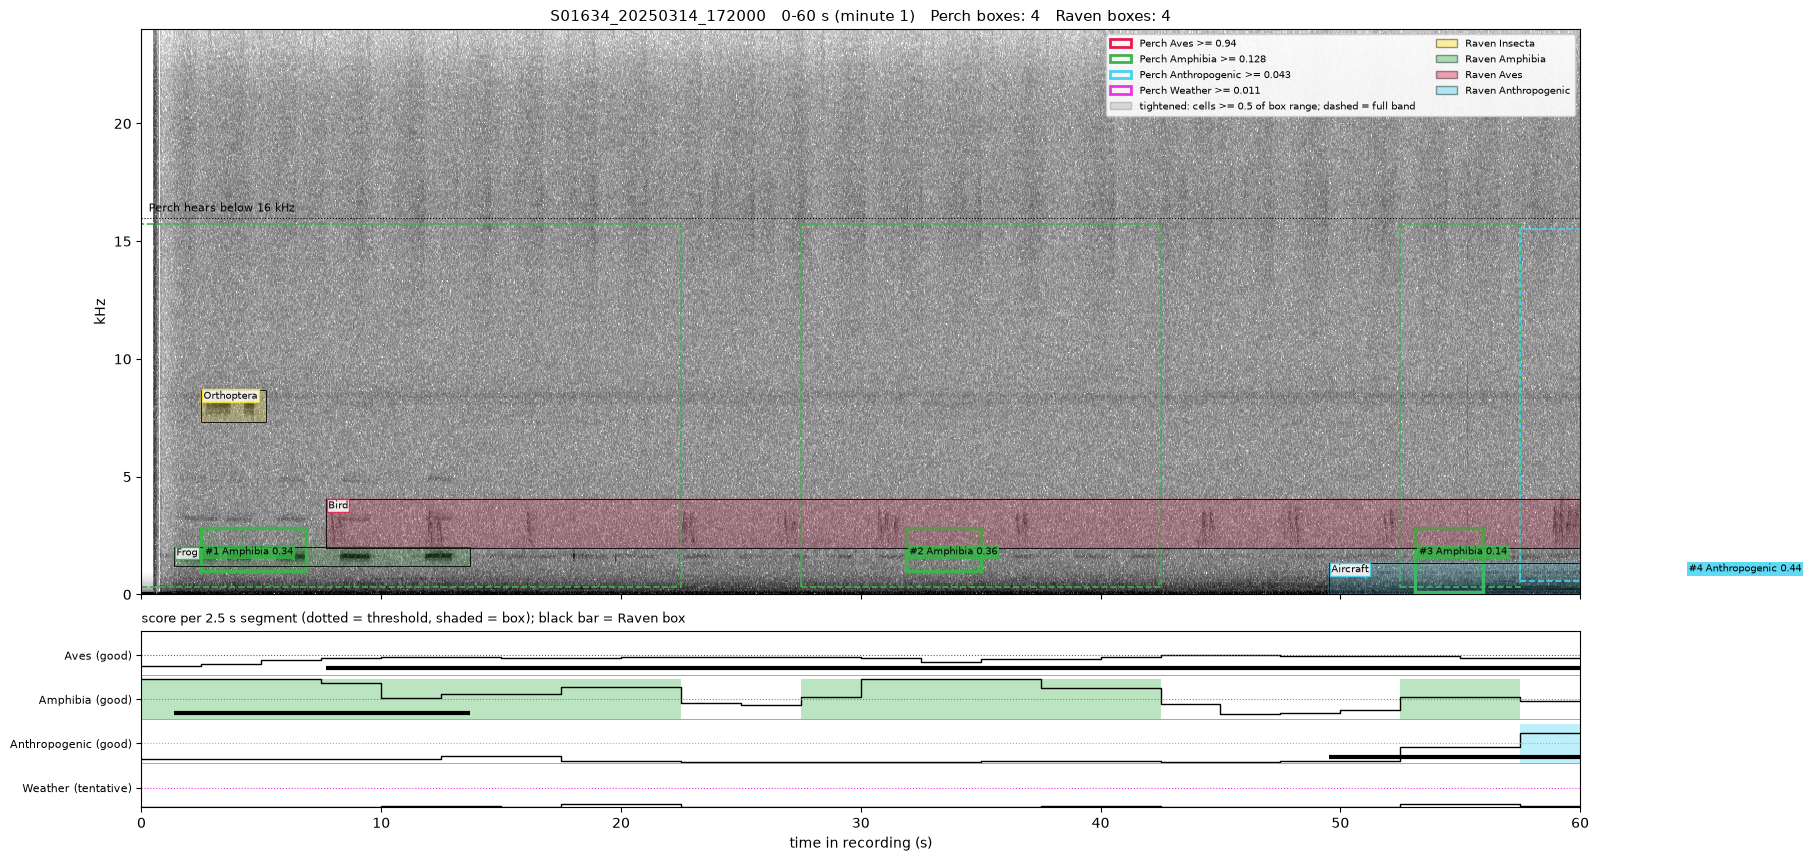

,group,begin_s,end_s,max_prob,n_segments,t_begin,t_end,lo_khz,hi_khz,area,kept
0,Amphibia,0.0,22.5,0.339016,9,2.500,6.8750,0.955,2.864,0.048611,"[[False, True, False, False], [False, True, Fa..."
1,Amphibia,27.5,42.5,0.356609,6,31.875,35.0000,0.955,2.864,0.052083,"[[False, True, False, False], [False, False, F..."
2,Amphibia,52.5,57.5,0.143104,2,53.125,55.9375,0.060,2.864,0.281250,"[[False, True, False, False], [False, False, F..."
3,Anthropogenic,57.5,87.5,0.439029,12,64.375,80.9375,0.955,2.864,0.138021,"[[False, True, False, False], [False, True, Fa..."


In [5]:
fig, pb, rv = pv.plot_page("S01634_20250314_172000", t0=0, seg=seg, raven=raven, wavs=viewer.wavs,
                           groups=["Aves", "Amphibia", "Anthropogenic", "Weather"], show_raven=True,
                           cells=viewer.cells, box_mode="both", kappa=0.5)
plt.show()
pb  # the Perch boxes on this page